In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print("Environment ready.")

Environment ready.


Load the Cleaned Cycle-Level Dataset
Load cycles_clean.csv, the main processed dataset containing valid discharge cycles and their associated operating conditions, capacity measurements, and SOH values.


In [2]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed" / "cycles_clean.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cycles_clean.csv"

cycles = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {cycles.shape}")
cycles.head()


Dataset shape: (2658, 40)


,battery_id,group,op_index,cycle,cycle_valid,segment,start_time,ambient_C,I_level_A,profile,discharge_cutoff_V,capacity_Ah,capacity_to_2p7V_Ah,capacity_int_Ah,C0_Ah,soh_segment,soh,I_load_mean_A,V_min,duration_s,t_to_cutoff_s,energy_Wh,T_start_C,T_max_C,T_mean_C,chg_op_index,chg_duration_s,chg_end_time,chg_charge_Ah,chg_cc_time_s,chg_T_max_C,rest_before_h,n_chg_since_prev_dis,eis_op_index,Re_ohm,Rct_ohm,cap_outlier,break_in,long_rest,tier
0,B0005,G1,1,1,1,1,2008-04-02 15:25:41.593,24.0,2.0,constant_current,2.7,1.856487,1.856469,1.862016,1.851883,1.005472,1.005472,2.012621,2.612467,3690.234,3346.937,6.608164,24.330034,38.982181,32.572328,0.0,7597.875,2008-04-02 15:14:55.796,0.738393,667.891,27.445134,0.179388,1,NaN,NaN,NaN,False,False,False,A
1,B0005,G1,3,2,2,1,2008-04-02 19:43:48.406,24.0,2.0,constant_current,2.7,1.846327,1.846323,1.851883,1.851883,1.000000,1.000000,2.012561,2.587209,3672.344,3328.828,6.585710,24.697752,39.033398,32.725235,2.0,10516.000,2008-04-02 19:33:07.984,1.838209,3241.797,29.341949,0.177895,1,NaN,NaN,NaN,False,False,False,A
2,B0005,G1,5,3,3,1,2008-04-03 00:01:06.687,24.0,2.0,constant_current,2.7,1.835349,1.835336,1.840889,1.851883,0.994063,0.994063,2.012474,2.651917,3651.641,3309.422,6.555154,24.734266,38.818797,32.642862,4.0,10484.547,2008-04-02 23:50:25.359,1.832306,3238.719,29.553301,0.178147,1,NaN,NaN,NaN,False,False,False,A
3,B0005,G1,7,4,4,1,2008-04-03 04:16:37.375,24.0,2.0,constant_current,2.7,1.835263,1.835257,1.840781,1.851883,0.994005,0.994005,2.012181,2.592948,3631.563,3309.719,6.554398,24.654236,38.762305,32.514876,6.0,10397.890,2008-04-03 04:05:56.561,1.825609,3229.203,29.456340,0.178004,1,NaN,NaN,NaN,False,False,False,A
4,B0005,G1,9,5,5,1,2008-04-03 08:33:25.703,24.0,2.0,constant_current,2.7,1.834646,1.834635,1.840185,1.851883,0.993683,0.993683,2.012707,2.547420,3629.172,3307.688,6.551641,24.524797,38.665393,32.382349,8.0,10495.203,2008-04-03 08:22:44.328,1.823700,3228.218,29.481334,0.178160,1,NaN,NaN,NaN,False,False,False,A


Prepare the Regression Dataset
Filter the cleaned dataset to Tier A batteries and exclude capacity outliers and break-in cycles, following the project preprocessing rules for multiple log-linear regression.

In [3]:
regression_df = cycles[
    (cycles["tier"] == "A")
    & (~cycles["cap_outlier"])
    & (~cycles["break_in"])
].copy()

print(f"Regression dataset shape: {regression_df.shape}")
print(f"Number of batteries: {regression_df['battery_id'].nunique()}")
print(f"Batteries: {regression_df['battery_id'].unique()}")

Regression dataset shape: (1475, 40)
Number of batteries: 12
Batteries: <StringArray>
['B0005', 'B0006', 'B0007', 'B0018', 'B0033', 'B0034', 'B0045', 'B0046', 'B0047', 'B0048', 'B0055', 'B0056']
Length: 12, dtype: str


Select Variables for Regression Analysis
Extract the main identification, operating-condition, degradation, and SOH variables required for the regression analysis.

In [4]:
regression_columns = [
    "battery_id",
    "group",
    "cycle_valid",
    "ambient_C",
    "I_level_A",
    "discharge_cutoff_V",
    "profile",
    "capacity_int_Ah",
    "C0_Ah",
    "soh",
    "T_max_C",
    "long_rest",
]

regression_df[regression_columns].head(10)

,battery_id,group,cycle_valid,ambient_C,I_level_A,discharge_cutoff_V,profile,capacity_int_Ah,C0_Ah,soh,T_max_C,long_rest
0,B0005,G1,1,24.0,2.0,2.7,constant_current,1.862016,1.851883,1.005472,38.982181,False
1,B0005,G1,2,24.0,2.0,2.7,constant_current,1.851883,1.851883,1.000000,39.033398,False
2,B0005,G1,3,24.0,2.0,2.7,constant_current,1.840889,1.851883,0.994063,38.818797,False
3,B0005,G1,4,24.0,2.0,2.7,constant_current,1.840781,1.851883,0.994005,38.762305,False
4,B0005,G1,5,24.0,2.0,2.7,constant_current,1.840185,1.851883,0.993683,38.665393,False
5,B0005,G1,6,24.0,2.0,2.7,constant_current,1.841180,1.851883,0.994221,38.751695,False
6,B0005,G1,7,24.0,2.0,2.7,constant_current,1.840655,1.851883,0.993937,38.820701,False
7,B0005,G1,8,24.0,2.0,2.7,constant_current,1.831294,1.851883,0.988882,38.517130,False
8,B0005,G1,9,24.0,2.0,2.7,constant_current,1.830305,1.851883,0.988348,38.526268,False
9,B0005,G1,10,24.0,2.0,2.7,constant_current,1.830127,1.851883,0.988252,38.526981,False


Check Missing Values
Verify that the variables selected for regression contain no missing values before proceeding with statistical analysis and model fitting.


In [5]:
regression_df[regression_columns].isna().sum()

battery_id            0
group                 0
cycle_valid           0
ambient_C             0
I_level_A             0
discharge_cutoff_V    0
profile               0
capacity_int_Ah       0
C0_Ah                 0
soh                   0
T_max_C               0
long_rest             0
dtype: int64

Inspect Battery Operating Conditions
Summarize the temperature, discharge current, cutoff voltage, and discharge profile of each Tier A battery to understand the experimental conditions represented in the regression dataset.

In [6]:
battery_conditions = (
    regression_df[
        [
            "battery_id",
            "group",
            "ambient_C",
            "I_level_A",
            "discharge_cutoff_V",
            "profile",
        ]
    ]
    .drop_duplicates()
    .sort_values("battery_id")
)

battery_conditions

,battery_id,group,ambient_C,I_level_A,discharge_cutoff_V,profile
0,B0005,G1,24.0,2.0,2.7,constant_current
168,B0006,G1,24.0,2.0,2.5,constant_current
336,B0007,G1,24.0,2.0,2.2,constant_current
504,B0018,G1,24.0,2.0,2.5,constant_current
910,B0033,G4,24.0,4.0,2.0,constant_current
1100,B0034,G4,24.0,4.0,2.2,constant_current
2028,B0045,G7,4.0,1.0,2.0,constant_current
2097,B0046,G7,4.0,1.0,2.2,constant_current
2165,B0047,G7,4.0,1.0,2.5,constant_current
2233,B0048,G7,4.0,1.0,2.7,constant_current


Count Valid Cycles per Battery
Calculate the number of usable discharge cycles contributed by each battery after preprocessing and filtering.

In [7]:
battery_counts = (
    regression_df.groupby("battery_id")
    .size()
    .reset_index(name="n_cycles")
    .sort_values("battery_id")
)

battery_counts

,battery_id,n_cycles
0,B0005,167
1,B0006,166
2,B0007,167
3,B0018,132
4,B0033,178
5,B0034,194
6,B0045,67
7,B0046,68
8,B0047,68
9,B0048,68


Descriptive Statistics of Regression Variables
Summarize the distribution, central tendency, and variability of cycle number, operating conditions, capacity, SOH, and battery temperature.

In [8]:
summary_columns = [
    "cycle_valid",
    "ambient_C",
    "I_level_A",
    "discharge_cutoff_V",
    "capacity_int_Ah",
    "C0_Ah",
    "soh",
    "T_max_C",
]

regression_df[summary_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
cycle_valid,1475.0,72.870508,49.707805,1.000000,32.000000,63.000000,108.000000,196.000000
ambient_C,1475.0,17.613559,9.327442,4.000000,4.000000,24.000000,24.000000,24.000000
I_level_A,1475.0,2.320678,1.044245,1.000000,2.000000,2.000000,4.000000,4.000000
discharge_cutoff_V,1475.0,2.375254,0.247575,2.000000,2.200000,2.500000,2.500000,2.700000
capacity_int_Ah,1475.0,1.450186,0.252249,0.746121,1.269549,1.462644,1.615533,2.046695
C0_Ah,1475.0,1.706246,0.259296,1.030535,1.532278,1.796863,1.856590,2.036557
soh,1475.0,0.851485,0.085699,0.575568,0.799989,0.848826,0.915780,1.041322
T_max_C,1475.0,35.552503,15.946647,10.196290,16.311567,39.182874,51.022480,61.137160


Correlation Analysis of Key Variables
Compute the Pearson correlation matrix to examine the initial linear relationships among cycle number, operating conditions, maximum battery temperature, and SOH.


In [9]:
correlation_columns = [
    "cycle_valid",
    "ambient_C",
    "I_level_A",
    "discharge_cutoff_V",
    "T_max_C",
    "soh",
]

correlation_matrix = regression_df[correlation_columns].corr()

correlation_matrix

,cycle_valid,ambient_C,I_level_A,discharge_cutoff_V,T_max_C,soh
cycle_valid,1.000000,0.431510,0.389254,-0.165175,0.497716,-0.685037
ambient_C,0.431510,1.000000,0.587923,-0.227128,0.908645,-0.069305
I_level_A,0.389254,0.587923,1.000000,-0.511964,0.850962,0.128716
discharge_cutoff_V,-0.165175,-0.227128,-0.511964,1.000000,-0.455013,-0.069394
T_max_C,0.497716,0.908645,0.850962,-0.455013,1.000000,-0.031489
soh,-0.685037,-0.069305,0.128716,-0.069394,-0.031489,1.000000


SOH Degradation Curves by Battery
Visualize SOH against valid cycle number for each Tier A battery to compare degradation trajectories and identify differences in ageing rates across batteries.

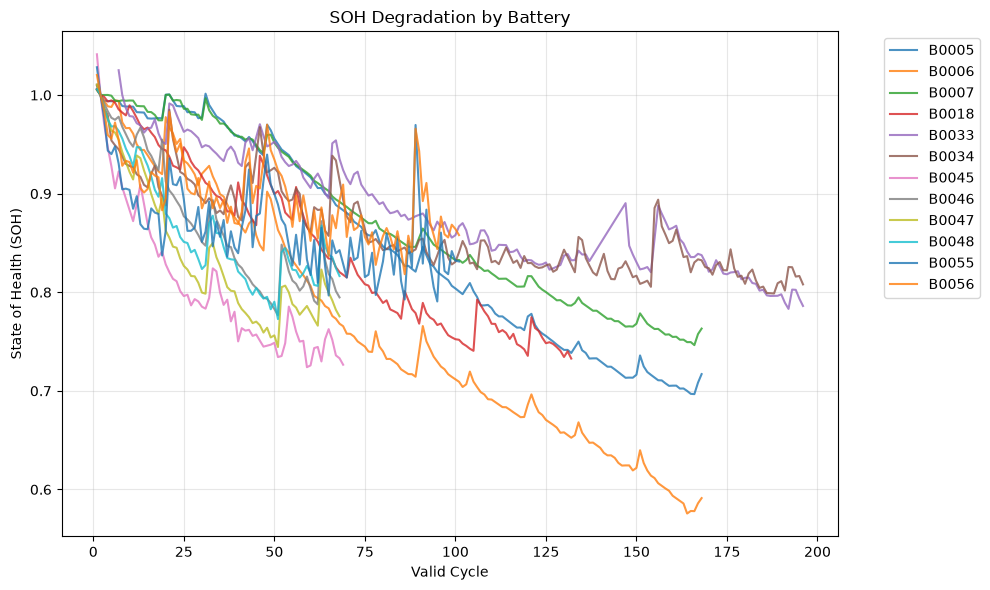

In [10]:
plt.figure(figsize=(10, 6))

for battery_id, battery_data in regression_df.groupby("battery_id"):
    plt.plot(
        battery_data["cycle_valid"],
        battery_data["soh"],
        label=battery_id,
        alpha=0.8,
    )

plt.xlabel("Valid Cycle")
plt.ylabel("State of Health (SOH)")
plt.title("SOH Degradation by Battery")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Correlation Between Cycle Number and SOH
Quantify the overall linear association between valid cycle number and SOH as an initial measure of battery degradation over repeated discharge cycles.

In [11]:
cycle_soh_corr = regression_df["cycle_valid"].corr(regression_df["soh"])

print(f"Correlation between cycle_valid and SOH: {cycle_soh_corr:.4f}")

Correlation between cycle_valid and SOH: -0.6850

### Baseline Simple Regression
Fit SOH on valid cycle number using statsmodels. The slope is an average association per valid cycle, not a causal effect. Report uncertainty, fit statistics, and residual checks before extending the model.

,coefficient,standard_error,t_statistic,p_value,ci_low,ci_high
Intercept,0.937548,0.002886,324.816629,0.000000e+00,0.931887,0.943210
cycle_valid,-0.001181,0.000033,-36.089487,7.044647e-205,-0.001245,-0.001117


R2 0.469275464390536 adjusted R2 0.468915162601256 F 1302.4511072461773 F_p 7.044647030898592e-205
Cycle slope in SOH per valid cycle: -0.0011810433587354755


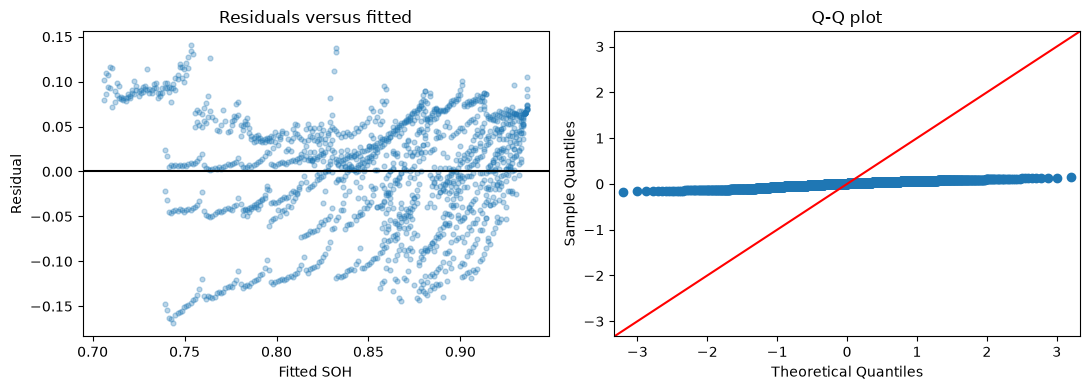

Breusch-Pagan LM, p: 92.93646785328272 5.400026321086385e-22 ; row-order Durbin-Watson: 0.09958058121585162
Pooled row-order autocorrelation is descriptive only because rows combine repeated battery series.


In [12]:
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

simple_fit = smf.ols('soh ~ cycle_valid', data=regression_df).fit()
ci = simple_fit.conf_int()
simple_table = pd.DataFrame({'coefficient':simple_fit.params,'standard_error':simple_fit.bse,'t_statistic':simple_fit.tvalues,'p_value':simple_fit.pvalues,'ci_low':ci[0],'ci_high':ci[1]})
display(simple_table)
print('R2',simple_fit.rsquared,'adjusted R2',simple_fit.rsquared_adj,'F',simple_fit.fvalue,'F_p',simple_fit.f_pvalue)
print('Cycle slope in SOH per valid cycle:',simple_fit.params['cycle_valid'])
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(simple_fit.fittedvalues,simple_fit.resid,alpha=.3,s=12); ax[0].axhline(0,color='black')
ax[0].set(xlabel='Fitted SOH',ylabel='Residual',title='Residuals versus fitted')
sm.qqplot(simple_fit.resid,line='45',ax=ax[1]); ax[1].set_title('Q-Q plot')
fig.tight_layout(); fig.savefig(PROJECT_ROOT/'reports'/'figures'/'regression_simple_diagnostics.png',dpi=160,bbox_inches='tight'); plt.show()
bp=het_breuschpagan(simple_fit.resid,simple_fit.model.exog)
print('Breusch-Pagan LM, p:',bp[0],bp[1],'; row-order Durbin-Watson:',durbin_watson(simple_fit.resid))
print('Pooled row-order autocorrelation is descriptive only because rows combine repeated battery series.')

### Compare Functional Forms
Compare the existing SOH linear baseline with the required log-linear and quadratic alternatives. SOH must be positive before taking logs. Report formula, R-squared, adjusted R-squared, AIC, BIC, and original-scale RMSE. AIC/BIC from models with different response scales are not directly comparable; interpret fit statistics with residual patterns and the degradation interpretation.

,model,formula,R2,adjusted_R2,AIC,BIC,RMSE_SOH
0,Linear SOH,soh ~ cycle_valid,0.469275,0.468915,-3993.453683,-3982.860857,0.062411
1,Log-linear SOH,ln(soh) ~ cycle_valid,0.455166,0.454796,-3383.458790,-3372.865964,0.061779
2,Quadratic SOH,soh ~ cycle_valid + I(cycle_valid ** 2),0.524796,0.524150,-4154.439148,-4138.549908,0.059057


Log-linear cycle coefficient: -0.0014116989103514779 approximate percent change/cycle: -0.1411698910351478 exact percent change/cycle: -0.1410702932173602


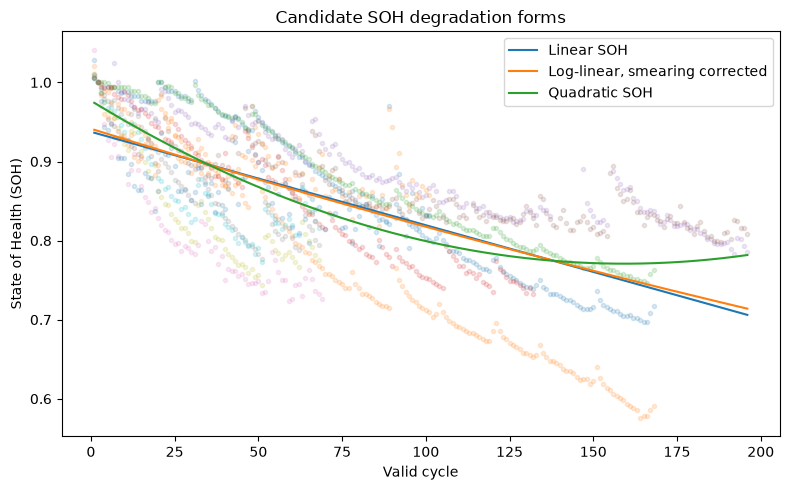

In [13]:
assert (regression_df['soh'] > 0).all(), 'All SOH values must be positive before log transformation.'
regression_df['ln_soh'] = np.log(regression_df['soh'])
linear_fit = simple_fit
loglinear_fit = smf.ols('ln_soh ~ cycle_valid', data=regression_df).fit()
quadratic_fit = smf.ols('soh ~ cycle_valid + I(cycle_valid ** 2)', data=regression_df).fit()
smearing_factor = np.mean(np.exp(loglinear_fit.resid))
candidate_models = [
    ('Linear SOH', 'soh ~ cycle_valid', linear_fit, regression_df['soh'], linear_fit.fittedvalues),
    ('Log-linear SOH', 'ln(soh) ~ cycle_valid', loglinear_fit, regression_df['ln_soh'], smearing_factor * np.exp(loglinear_fit.fittedvalues)),
    ('Quadratic SOH', 'soh ~ cycle_valid + I(cycle_valid ** 2)', quadratic_fit, regression_df['soh'], quadratic_fit.fittedvalues),
]
form_rows = []
for name, formula, fit, observed, predicted_soh in candidate_models:
    form_rows.append({'model':name,'formula':formula,'R2':fit.rsquared,'adjusted_R2':fit.rsquared_adj,
                      'AIC':fit.aic,'BIC':fit.bic,'RMSE_SOH':float(np.sqrt(np.mean((regression_df['soh']-predicted_soh)**2)))})
form_comparison = pd.DataFrame(form_rows)
display(form_comparison)
print('Log-linear cycle coefficient:', loglinear_fit.params['cycle_valid'],
      'approximate percent change/cycle:', 100*loglinear_fit.params['cycle_valid'],
      'exact percent change/cycle:', 100*(np.exp(loglinear_fit.params['cycle_valid'])-1))
x_grid=np.linspace(regression_df.cycle_valid.min(),regression_df.cycle_valid.max(),250)
fig,ax=plt.subplots(figsize=(8,5))
for battery_id,g in regression_df.groupby('battery_id'): ax.scatter(g.cycle_valid,g.soh,s=9,alpha=.16)
ax.plot(x_grid,linear_fit.predict(pd.DataFrame({'cycle_valid':x_grid})),label='Linear SOH')
ax.plot(x_grid,smearing_factor*np.exp(loglinear_fit.predict(pd.DataFrame({'cycle_valid':x_grid}))),label='Log-linear, smearing corrected')
ax.plot(x_grid,quadratic_fit.predict(pd.DataFrame({'cycle_valid':x_grid})),label='Quadratic SOH')
ax.set(xlabel='Valid cycle',ylabel='State of Health (SOH)',title='Candidate SOH degradation forms'); ax.legend()
fig.tight_layout(); fig.savefig(PROJECT_ROOT/'reports'/'figures'/'regression_functional_forms.png',dpi=160,bbox_inches='tight'); plt.show()

### Multiple Log-Linear Model Selection
Build the prescribed model from operating conditions and interactions. The main effects for a retained interaction stay in its group. Temperature is categorical; current and cutoff are continuous. Profile is included only if it varies in the regression subset. Selection uses parameter names and explicit Wald restrictions, without relying on patsy design metadata. The cycle main effect is retained in every model.

In [14]:
print('Tier A analysis rows:',len(regression_df),'batteries:',regression_df.battery_id.nunique())
display(regression_df[['ambient_C','I_level_A','discharge_cutoff_V','profile','T_max_C']].describe(include='all').T)
condition_rows=regression_df[['battery_id','ambient_C','I_level_A','discharge_cutoff_V','profile']].drop_duplicates()
display(pd.crosstab(condition_rows.ambient_C,condition_rows.I_level_A,margins=True))
display(pd.crosstab(condition_rows.ambient_C,condition_rows.discharge_cutoff_V,margins=True))
print('Profile levels in Tier A:', sorted(regression_df.profile.dropna().astype(str).unique()))
print('T_max_C is not included as a primary operating-condition predictor because it is a correlated thermal response.')
regression_df['cycle_c']=regression_df['cycle_valid']-regression_df['cycle_valid'].mean()
regression_df['current_c']=regression_df['I_level_A']-regression_df['I_level_A'].mean()
regression_df['cutoff_c']=regression_df['discharge_cutoff_V']-regression_df['discharge_cutoff_V'].mean()
print('Cycle, current, and cutoff are centered at their regression-sample means to make main effects interpretable at typical conditions and reduce nonessential interaction collinearity.')
def make_log_formula(active):
    terms=['cycle_c']
    if 'ambient_C' in active: terms += ['C(ambient_C)','cycle_c:C(ambient_C)']
    if 'I_level_A' in active: terms += ['current_c','cycle_c:current_c']
    if 'discharge_cutoff_V' in active: terms += ['cutoff_c','cycle_c:cutoff_c']
    if 'profile' in active: terms += ['C(profile)']
    return 'ln_soh ~ ' + ' + '.join(terms)
def group_parameter_indices(param_names, group):
    if group=='ambient_C':
        return [i for i,n in enumerate(param_names) if n.startswith('C(ambient_C)[') or n.startswith('cycle_c:C(ambient_C)[')]
    if group=='I_level_A':
        return [i for i,n in enumerate(param_names) if n in ('current_c','cycle_c:current_c')]
    if group=='discharge_cutoff_V':
        return [i for i,n in enumerate(param_names) if n in ('cutoff_c','cycle_c:cutoff_c')]
    if group=='profile':
        return [i for i,n in enumerate(param_names) if n.startswith('C(profile)[')]
    return []
candidate_groups=['ambient_C','I_level_A','discharge_cutoff_V']
if regression_df.profile.nunique(dropna=True)>1: candidate_groups.append('profile')
selection_rows=[]
active_groups=candidate_groups.copy()
while True:
    selection_fit=smf.ols(make_log_formula(active_groups),data=regression_df).fit()
    group_pvalues={}
    for group in active_groups:
        idx=group_parameter_indices(selection_fit.params.index,group)
        if idx:
            restriction=np.eye(len(selection_fit.params))[idx,:]
            group_pvalues[group]=float(np.asarray(selection_fit.f_test(restriction).pvalue).squeeze())
    removable={name:pval for name,pval in group_pvalues.items() if pval>0.05}
    selection_rows.append({'formula':make_log_formula(active_groups),'adjusted_R2':selection_fit.rsquared_adj,
                           'AIC':selection_fit.aic,'group_pvalues':group_pvalues,
                           'removed':max(removable,key=removable.get) if removable else 'none'})
    if not removable: break
    active_groups.remove(max(removable,key=removable.get))
display(pd.DataFrame(selection_rows))
preferred_formula=make_log_formula(active_groups)
preferred_fit=smf.ols(preferred_formula,data=regression_df).fit()

Tier A analysis rows: 1475 batteries: 12


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ambient_C,1475.0,NaN,NaN,NaN,17.613559,9.327442,4.0,4.0,24.0,24.0,24.0
I_level_A,1475.0,NaN,NaN,NaN,2.320678,1.044245,1.0,2.0,2.0,4.0,4.0
discharge_cutoff_V,1475.0,NaN,NaN,NaN,2.375254,0.247575,2.0,2.2,2.5,2.5,2.7
profile,1475,1,constant_current,1475,NaN,NaN,NaN,NaN,NaN,NaN,NaN
T_max_C,1475.0,NaN,NaN,NaN,35.552503,15.946647,10.19629,16.311567,39.182874,51.02248,61.13716


I_level_A,1.0,2.0,4.0,All
ambient_C,,,,
4.0,4,2,0,6
24.0,0,4,2,6
All,4,6,2,12


discharge_cutoff_V,2.0,2.2,2.5,2.7,All
ambient_C,,,,,
4.0,1,1,2,2,6
24.0,1,2,2,1,6
All,2,3,4,3,12


Profile levels in Tier A: ['constant_current']
T_max_C is not included as a primary operating-condition predictor because it is a correlated thermal response.
Cycle, current, and cutoff are centered at their regression-sample means to make main effects interpretable at typical conditions and reduce nonessential interaction collinearity.


,formula,adjusted_R2,AIC,group_pvalues,removed
0,ln_soh ~ cycle_c + C(ambient_C) + cycle_c:C(am...,0.745485,-4501.133576,"{'ambient_C': 1.4579451855632126e-30, 'I_level...",none


### Preferred Model Estimates and Interaction Interpretation
Present conventional OLS and battery-clustered uncertainty for the selected formula. Coefficients for main effects in an interaction model are conditional on the other interacting variable values or reference categories. Cycle and continuous conditions are mean-centered, so main effects are conditional at typical cycle/current/cutoff values. For retained cycle interactions, transform the log-slope contrast into a relative per-cycle SOH ratio change.

In [15]:
cluster_fit=preferred_fit.get_robustcov_results(cov_type='cluster',groups=regression_df['battery_id'],use_correction=True)
cluster_ci=cluster_fit.conf_int()
coefficient_table=pd.DataFrame({'term':preferred_fit.params.index,'coefficient':preferred_fit.params.values,
 'OLS_SE':preferred_fit.bse.values,'OLS_p_value':preferred_fit.pvalues.values,
 'cluster_SE':cluster_fit.bse,'cluster_p_value':cluster_fit.pvalues,
 'cluster_CI_low':cluster_ci[:,0],'cluster_CI_high':cluster_ci[:,1]})
display(coefficient_table)
print('Selected formula:',preferred_formula)
print(f'R2={preferred_fit.rsquared:.4f}; adjusted R2={preferred_fit.rsquared_adj:.4f}; AIC={preferred_fit.aic:.2f}; BIC={preferred_fit.bic:.2f}')
interaction_rows=[]
for term in preferred_fit.params.index:
    if not term.startswith('cycle_c:'): continue
    j=preferred_fit.params.index.get_loc(term); beta=float(preferred_fit.params.iloc[j]); lo,hi=cluster_ci[j]
    interaction_rows.append({'interaction':term,'coefficient':beta,'cluster_p_value':cluster_fit.pvalues[j],
       'cluster_CI_low':lo,'cluster_CI_high':hi,'relative_cycle_ratio_change_pct':100*(np.exp(beta)-1),
       'relative_change_CI_low_pct':100*(np.exp(lo)-1),'relative_change_CI_high_pct':100*(np.exp(hi)-1)})
interaction_table=pd.DataFrame(interaction_rows)
display(interaction_table)
print('Ambient-category interactions compare log-SOH cycle slopes with the reference temperature. Current and cutoff interactions express the slope contrast per ampere or volt, conditional on other model terms.')

,term,coefficient,OLS_SE,OLS_p_value,cluster_SE,cluster_p_value,cluster_CI_low,cluster_CI_high
0,Intercept,-0.178729,0.004041,3.476140e-272,0.026239,0.000029,-0.236480,-0.120977
1,C(ambient_C)[T.24.0],0.013690,0.004586,2.880427e-03,0.039240,0.733762,-0.072676,0.100057
2,cycle_c,-0.001210,0.000101,1.226323e-31,0.000451,0.021398,-0.002203,-0.000216
3,cycle_c:C(ambient_C)[T.24.0],-0.000996,0.000112,2.240208e-18,0.000519,0.081124,-0.002138,0.000146
4,current_c,0.037056,0.001988,9.364250e-70,0.020492,0.097948,-0.008047,0.082158
5,cycle_c:current_c,0.000544,0.000040,4.936692e-40,0.000276,0.074390,-0.000063,0.001151
6,cutoff_c,0.016229,0.006990,2.038052e-02,0.074509,0.831565,-0.147764,0.180221
7,cycle_c:cutoff_c,-0.001149,0.000153,8.995223e-14,0.001110,0.322909,-0.003593,0.001295


Selected formula: ln_soh ~ cycle_c + C(ambient_C) + cycle_c:C(ambient_C) + current_c + cycle_c:current_c + cutoff_c + cycle_c:cutoff_c
R2=0.7467; adjusted R2=0.7455; AIC=-4501.13; BIC=-4458.76


,interaction,coefficient,cluster_p_value,cluster_CI_low,cluster_CI_high,relative_cycle_ratio_change_pct,relative_change_CI_low_pct,relative_change_CI_high_pct
0,cycle_c:C(ambient_C)[T.24.0],-0.000996,0.081124,-0.002138,0.000146,-0.099570,-0.213577,0.014568
1,cycle_c:current_c,0.000544,0.074390,-0.000063,0.001151,0.054409,-0.006343,0.115199
2,cycle_c:cutoff_c,-0.001149,0.322909,-0.003593,0.001295,-0.114863,-0.358699,0.129570


Ambient-category interactions compare log-SOH cycle slopes with the reference temperature. Current and cutoff interactions express the slope contrast per ampere or volt, conditional on other model terms.


### VIF and Preferred-Model Diagnostics
Inspect multicollinearity in the fitted design, residual shape, heteroskedasticity, leverage, Cook distance, and serial dependence within each battery. Cluster-robust standard errors do not make cycles independent; the independent battery-level regression is reported separately.

,variable,VIF
1,cycle_c,13.482507
2,cycle_c:C(ambient_C)[T.24.0],12.528305
4,cycle_c:current_c,2.578565
0,C(ambient_C)[T.24.0],2.448775
3,current_c,2.307300
6,cycle_c:cutoff_c,1.952201
5,cutoff_c,1.603101


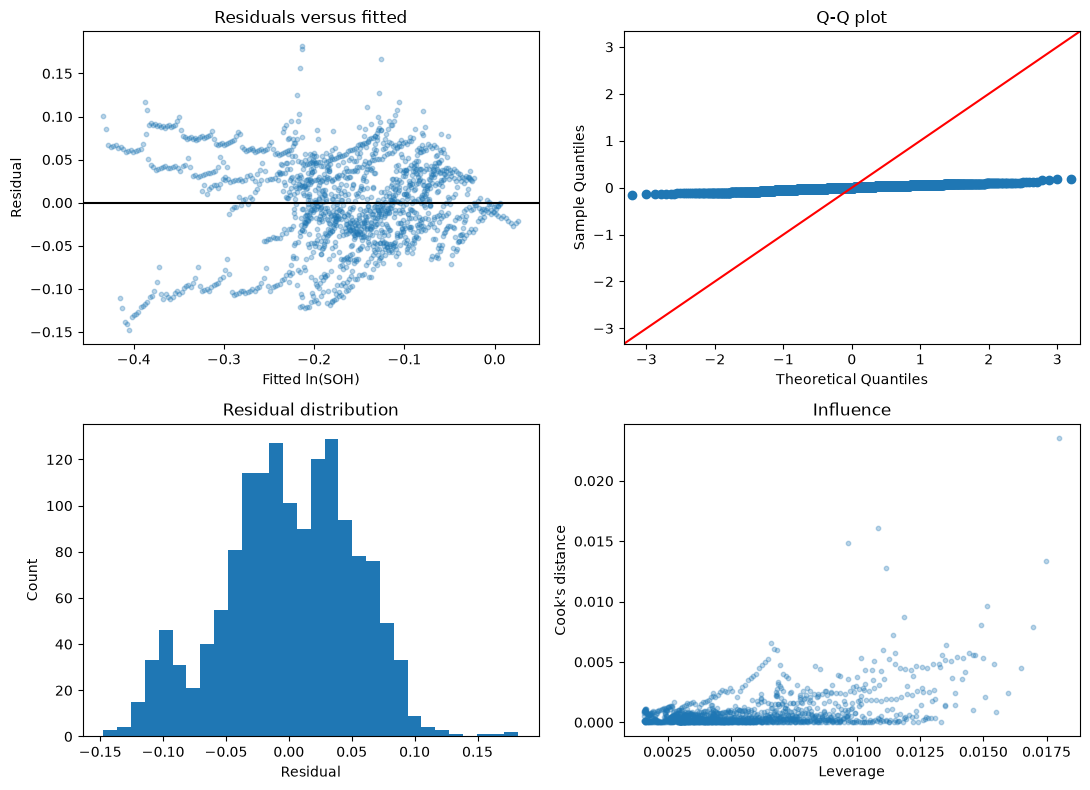

Breusch-Pagan LM: 367.7947972892626 p-value: 1.9061153889487313e-75
Observations with Cook distance > 4/n: 87 maximum leverage: 0.01800220882277351


,battery_id,cycle_valid,fitted,residual,leverage,cooks_distance
1004,B0045,1,-0.126167,0.166658,0.018002,0.023539
1462,B0056,89,-0.213690,0.178945,0.010818,0.016071
1362,B0055,89,-0.213228,0.182399,0.009633,0.014833
1005,B0045,2,-0.127664,0.127664,0.017479,0.013397
1463,B0056,90,-0.215448,0.156873,0.011155,0.012745
499,B0007,168,-0.387063,0.116762,0.015148,0.009666
1465,B0056,92,-0.218963,0.125570,0.011854,0.008690
498,B0007,167,-0.384884,0.107234,0.014901,0.008016
1006,B0045,3,-0.129161,0.099325,0.016968,0.007864
1071,B0046,1,-0.106401,0.117034,0.011403,0.007255


,Durbin_Watson
battery_id,
B0005,0.028931
B0006,0.020743
B0007,0.006259
B0018,0.290827
B0033,0.266176
B0034,0.260171
B0045,0.061113
B0046,0.162335
B0047,0.089827


,Durbin_Watson_by_battery
battery_id,
B0005,0.028931
B0006,0.020743
B0007,0.006259
B0018,0.290827
B0033,0.266176
B0034,0.260171
B0045,0.061113
B0046,0.162335
B0047,0.089827


Battery-specific Durbin-Watson values are descriptive checks of within-series residual autocorrelation.


In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X=preferred_fit.model.exog
vif_table=pd.DataFrame({'variable':preferred_fit.model.exog_names[1:],
 'VIF':[variance_inflation_factor(X,j) for j in range(1,X.shape[1])]})
display(vif_table.sort_values('VIF',ascending=False))
model_influence=preferred_fit.get_influence().summary_frame()
diagnostic_data=pd.DataFrame({'battery_id':regression_df.battery_id.to_numpy(),
 'cycle_valid':regression_df.cycle_valid.to_numpy(),'fitted':preferred_fit.fittedvalues.to_numpy(),
 'residual':preferred_fit.resid.to_numpy(),'leverage':model_influence['hat_diag'].to_numpy(),
 'cooks_distance':model_influence['cooks_d'].to_numpy()})
fig,ax=plt.subplots(2,2,figsize=(11,8))
ax[0,0].scatter(diagnostic_data.fitted,diagnostic_data.residual,s=10,alpha=.3); ax[0,0].axhline(0,color='black'); ax[0,0].set(xlabel='Fitted ln(SOH)',ylabel='Residual',title='Residuals versus fitted')
sm.qqplot(diagnostic_data.residual,line='45',ax=ax[0,1]); ax[0,1].set_title('Q-Q plot')
ax[1,0].hist(diagnostic_data.residual,bins=30); ax[1,0].set(title='Residual distribution',xlabel='Residual',ylabel='Count')
ax[1,1].scatter(diagnostic_data.leverage,diagnostic_data.cooks_distance,s=10,alpha=.3); ax[1,1].set(xlabel='Leverage',ylabel="Cook's distance",title='Influence')
fig.tight_layout(); fig.savefig(PROJECT_ROOT/'reports'/'figures'/'regression_preferred_diagnostics.png',dpi=160,bbox_inches='tight'); plt.show()
bp=het_breuschpagan(preferred_fit.resid,preferred_fit.model.exog)
print('Breusch-Pagan LM:',bp[0],'p-value:',bp[1])
print('Observations with Cook distance > 4/n:',int((diagnostic_data.cooks_distance>4/len(diagnostic_data)).sum()),'maximum leverage:',diagnostic_data.leverage.max())
display(diagnostic_data.nlargest(10,'cooks_distance'))
dw_by_battery=regression_df.assign(_resid=preferred_fit.resid.to_numpy()).sort_values(['battery_id','cycle_valid']).groupby('battery_id')['_resid'].apply(durbin_watson)
display(dw_by_battery.rename('Durbin_Watson').to_frame())
residual_ordered=regression_df[['battery_id','cycle_valid']].copy()
residual_ordered['residual']=preferred_fit.resid.to_numpy()
dw_by_battery=residual_ordered.sort_values(['battery_id','cycle_valid']).groupby('battery_id').residual.apply(durbin_watson)
display(dw_by_battery.rename('Durbin_Watson_by_battery').to_frame())
print('Battery-specific Durbin-Watson values are descriptive checks of within-series residual autocorrelation.')

### Battery-Level Ageing-Rate Regression
Use the processed one-row-per-battery table to address within-battery dependence. Regress full-span fade and the documented first-25-cycle fade on ambient temperature, current, and cutoff voltage. HC3 standard errors provide small-sample heteroskedasticity-robust inference; the limited sample and incomplete condition crossing constrain interpretation.

In [17]:
fade_data=pd.read_csv(PROJECT_ROOT/'data'/'processed'/'battery_fade.csv')
print('Battery-level sample size:',len(fade_data),'cells')
display(fade_data[['fade_pct_per_100cyc','fade25_pct_per_100cyc','ambient_C','I_level_A','discharge_cutoff_V']].describe().T)
display(fade_data.groupby(['ambient_C','I_level_A','profile','discharge_cutoff_V'],dropna=False).size().rename('n_batteries').reset_index())
fade_formula='fade_pct_per_100cyc ~ ambient_C + I_level_A + discharge_cutoff_V'
fade_fit=smf.ols(fade_formula,data=fade_data).fit(cov_type='HC3')
fade25_fit=smf.ols('fade25_pct_per_100cyc ~ ambient_C + I_level_A + discharge_cutoff_V',data=fade_data).fit(cov_type='HC3')
def fade_coefficient_table(fit):
    ci=fit.conf_int()
    return pd.DataFrame({'coefficient':fit.params,'HC3_SE':fit.bse,'p_value':fit.pvalues,'CI_low':ci[0],'CI_high':ci[1]})
display(fade_coefficient_table(fade_fit)); display(fade_coefficient_table(fade25_fit))
print('Full-span formula:',fade_formula,'n:',int(fade_fit.nobs),'R2:',fade_fit.rsquared,'adjusted R2:',fade_fit.rsquared_adj)
print('First-25-cycle n:',int(fade25_fit.nobs),'R2:',fade25_fit.rsquared,'adjusted R2:',fade25_fit.rsquared_adj)
print('Fade outcomes are SOH points per 100 cycles; coefficients are conditional associations, not causal effects.')

Battery-level sample size: 23 cells


,count,mean,std,min,25%,50%,75%,max
fade_pct_per_100cyc,23.0,18.515098,9.464228,5.861001,9.900875,16.998401,27.903157,32.012175
fade25_pct_per_100cyc,23.0,28.253001,20.890960,4.230354,13.977982,25.516642,35.832301,81.600941
ambient_C,23.0,20.347826,14.040878,4.000000,4.000000,24.000000,24.000000,43.000000
I_level_A,23.0,2.608696,1.196173,1.000000,2.000000,2.000000,4.000000,4.000000
discharge_cutoff_V,23.0,2.365217,0.270704,2.000000,2.200000,2.500000,2.600000,2.700000


,ambient_C,I_level_A,profile,discharge_cutoff_V,n_batteries
0,4.0,1.0,constant_current,2.0,1
1,4.0,1.0,constant_current,2.2,1
2,4.0,1.0,constant_current,2.5,1
3,4.0,1.0,constant_current,2.7,1
4,4.0,2.0,constant_current,2.0,1
5,4.0,2.0,constant_current,2.2,1
6,4.0,2.0,constant_current,2.5,1
7,4.0,2.0,constant_current,2.7,1
8,24.0,2.0,constant_current,2.2,1
9,24.0,2.0,constant_current,2.5,2


,coefficient,HC3_SE,p_value,CI_low,CI_high
Intercept,55.851415,21.111381,0.008156,14.473867,97.228962
ambient_C,0.691479,0.172658,0.000062,0.353075,1.029883
I_level_A,-8.652117,2.208073,0.000089,-12.979860,-4.324373
discharge_cutoff_V,-12.191552,7.867026,0.121213,-27.610639,3.227535


,coefficient,HC3_SE,p_value,CI_low,CI_high
Intercept,103.594047,60.365700,0.086142,-14.720550,221.908644
ambient_C,-0.095751,0.441224,0.828198,-0.960534,0.769032
I_level_A,-9.686363,6.230149,0.120004,-21.897232,2.524505
discharge_cutoff_V,-20.346519,21.530297,0.344650,-62.545125,21.852087


Full-span formula: fade_pct_per_100cyc ~ ambient_C + I_level_A + discharge_cutoff_V n: 23 R2: 0.434863027971765 adjusted R2: 0.3456308744936226
First-25-cycle n: 23 R2: 0.3579395521351215 adjusted R2: 0.2565615866827723
Fade outcomes are SOH points per 100 cycles; coefficients are conditional associations, not causal effects.


### Shared Cell-Holdout Evaluation: E1 and E2
Use the exact train/test batteries and scenarios in Rec.md. Select model terms from training batteries only, then fit on those rows. Convert log-SOH predictions back to the SOH scale before scoring. E1 uses one-step persistence; E2 holds the last observed SOH as a recursive naive forecast. EOL error is reported only when both observed and predicted SOH cross 0.8.

In [18]:
test_batteries=['B0007','B0034','B0047','B0055']
train_batteries=['B0005','B0006','B0018','B0033','B0045','B0046','B0048','B0056']
evaluation_data=regression_df[regression_df.battery_id.isin(train_batteries+test_batteries)].copy()
train_data=evaluation_data[evaluation_data.battery_id.isin(train_batteries)].copy()
test_data=evaluation_data[evaluation_data.battery_id.isin(test_batteries)].copy()
assert set(test_data.battery_id.unique())==set(test_batteries)
train_cycle_mean=train_data.cycle_valid.mean(); train_current_mean=train_data.I_level_A.mean(); train_cutoff_mean=train_data.discharge_cutoff_V.mean()
for frame in [evaluation_data,train_data,test_data]:
    frame['cycle_c']=frame.cycle_valid-train_cycle_mean
    frame['current_c']=frame.I_level_A-train_current_mean
    frame['cutoff_c']=frame.discharge_cutoff_V-train_cutoff_mean
print('Evaluation centering values are estimated on training batteries only.')
evaluation_groups=['ambient_C','I_level_A','discharge_cutoff_V']
if train_data.profile.nunique(dropna=True)>1: evaluation_groups.append('profile')
while True:
    selection_train_fit=smf.ols(make_log_formula(evaluation_groups),data=train_data).fit()
    train_group_p={}
    for group in evaluation_groups:
        idx=group_parameter_indices(selection_train_fit.params.index,group)
        if idx: train_group_p[group]=float(np.asarray(selection_train_fit.f_test(np.eye(len(selection_train_fit.params))[idx,:]).pvalue).squeeze())
    removable={k:v for k,v in train_group_p.items() if v>0.05}
    if not removable: break
    evaluation_groups.remove(max(removable,key=removable.get))
evaluation_formula=make_log_formula(evaluation_groups)
evaluation_fit=smf.ols(evaluation_formula,data=train_data).fit()
print('Training-only selected formula:',evaluation_formula)
prediction_parts=[]
for battery_id,g in test_data.sort_values('cycle_valid').groupby('battery_id'):
    g=g.sort_values('cycle_valid').copy(); n=len(g); origin=int(np.floor(.60*n))
    e1_start=max(origin,n-int(np.ceil(.40*n)))
    for scenario,positions in [('E1',np.arange(e1_start,n)),('E2',np.arange(origin,n))]:
        part=g.iloc[positions].copy(); part['scenario']=scenario
        part['y_pred']=np.exp(evaluation_fit.predict(part))
        part['model']='regression'; prediction_parts.append(part)
predictions=pd.concat(prediction_parts,ignore_index=True)
predictions['naive_pred']=np.nan
for (battery_id,scenario),idx in predictions.groupby(['battery_id','scenario']).groups.items():
    part=predictions.loc[idx].sort_values('cycle_valid')
    history=test_data[(test_data.battery_id==battery_id)&(test_data.cycle_valid<part.cycle_valid.iloc[0])].sort_values('cycle_valid')
    if not len(history): continue
    if scenario=='E2': predictions.loc[part.index,'naive_pred']=history.soh.iloc[-1]
    else:
        predictions.loc[part.index[0],'naive_pred']=history.soh.iloc[-1]
        for j in range(1,len(part)): predictions.loc[part.index[j],'naive_pred']=part.soh.iloc[j-1]
def regression_metrics(y_true,y_pred):
    y_true=np.asarray(y_true); y_pred=np.asarray(y_pred)
    return {'MAE':np.mean(np.abs(y_true-y_pred)),'RMSE':np.sqrt(np.mean((y_true-y_pred)**2)),
            'MAPE_pct':np.mean(np.abs((y_true-y_pred)/y_true))*100,
            'R2':1-np.sum((y_true-y_pred)**2)/np.sum((y_true-y_true.mean())**2)}
metric_rows=[]
for (scenario,battery_id),g in predictions.groupby(['scenario','battery_id']):
    for model,col in [('Log-linear regression','y_pred'),('Persistence baseline','naive_pred')]:
        valid=g.dropna(subset=[col]); metric_rows.append({'scenario':scenario,'battery_id':battery_id,'model':model,**regression_metrics(valid.soh,valid[col])})
metric_table=pd.DataFrame(metric_rows); display(metric_table)
display(metric_table.groupby(['scenario','model'])[['MAE','RMSE','MAPE_pct','R2']].mean())
rul_rows=[]
for battery_id,g in predictions[predictions.scenario=='E2'].groupby('battery_id'):
    actual=test_data[test_data.battery_id==battery_id].sort_values('cycle_valid')
    observed=actual.loc[actual.soh<=0.8,'cycle_valid']; forecast=g.loc[g.y_pred<=0.8,'cycle_valid']
    rul_rows.append({'battery_id':battery_id,'observed_EOL_cycle':observed.iloc[0] if len(observed) else np.nan,
       'predicted_E2_EOL_cycle':forecast.iloc[0] if len(forecast) else np.nan,
       'absolute_EOL_error_cycles':abs(observed.iloc[0]-forecast.iloc[0]) if len(observed) and len(forecast) else np.nan})
display(pd.DataFrame(rul_rows))
prediction_file=predictions[['model','battery_id','cycle_valid','scenario','soh','y_pred']].rename(columns={'soh':'y_true'})
prediction_file['y_lower']=np.nan; prediction_file['y_upper']=np.nan
prediction_file.to_csv(PROJECT_ROOT/'reports'/'predictions'/'regression.csv',index=False)
print('Point model intervals are unavailable; y_lower and y_upper remain missing. E2 persistence holds the SOH observed at the forecast origin.')

Evaluation centering values are estimated on training batteries only.
Training-only selected formula: ln_soh ~ cycle_c + C(ambient_C) + cycle_c:C(ambient_C) + current_c + cycle_c:current_c + cutoff_c + cycle_c:cutoff_c


,scenario,battery_id,model,MAE,RMSE,MAPE_pct,R2
0,E1,B0007,Log-linear regression,0.193393,0.194653,24.658331,-59.339825
1,E1,B0007,Persistence baseline,0.002812,0.003691,0.356200,0.978299
2,E1,B0034,Log-linear regression,0.083390,0.085176,10.128254,-21.938288
3,E1,B0034,Persistence baseline,0.008501,0.013483,1.015643,0.425234
4,E1,B0047,Log-linear regression,0.034068,0.041855,4.412752,-4.474364
5,E1,B0047,Persistence baseline,0.010234,0.017204,1.291808,0.075107
6,E1,B0055,Log-linear regression,0.024194,0.034395,2.864757,-0.275235
7,E1,B0055,Persistence baseline,0.034943,0.046189,4.126963,-1.299790
8,E2,B0007,Log-linear regression,0.193393,0.194653,24.658331,-59.339825
9,E2,B0007,Persistence baseline,0.045171,0.051522,5.839868,-3.227346


MAE      RMSE   MAPE_pct         R2
scenario model                                                          
E1       Log-linear regression  0.083761  0.089019  10.516024 -21.506928
         Persistence baseline   0.014122  0.020142   1.697653   0.044713
E2       Log-linear regression  0.083761  0.089019  10.516024 -21.506928
         Persistence baseline   0.023815  0.029969   2.987104  -0.871726

,battery_id,observed_EOL_cycle,predicted_E2_EOL_cycle,absolute_EOL_error_cycles
0,B0007,126,102.0,24.0
1,B0034,186,NaN,NaN
2,B0047,30,57.0,27.0
3,B0055,65,NaN,NaN


Point model intervals are unavailable; y_lower and y_upper remain missing. E2 persistence holds the SOH observed at the forecast origin.


## Key Findings
This summary is generated from the preceding executed code. Review the reported results before writing conclusions; no coefficient, significance, or metric is hard-coded.

In [19]:
print('Baseline cycle-SOH correlation:',round(cycle_soh_corr,4))
print('Regression observations:',len(regression_df),'Tier A batteries:',regression_df.battery_id.nunique())
print('Selected model:',preferred_formula)
print('Battery-level fade sample:',len(fade_data))
print('Interpret all effects conditionally and account for repeated cycles and incomplete experimental condition crossing.')

Baseline cycle-SOH correlation: -0.685
Regression observations: 1475 Tier A batteries: 12
Selected model: ln_soh ~ cycle_c + C(ambient_C) + cycle_c:C(ambient_C) + current_c + cycle_c:current_c + cutoff_c + cycle_c:cutoff_c
Battery-level fade sample: 23
Interpret all effects conditionally and account for repeated cycles and incomplete experimental condition crossing.
